In [1]:
!pip install -q xgboost

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import files
from sklearn.model_selection import (
    train_test_split, cross_val_score, GridSearchCV
)
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, classification_report,
    ConfusionMatrixDisplay, RocCurveDisplay
)

print("All libraries imported successfully!")

All libraries imported successfully!


In [3]:
from google.colab import files
uploaded = files.upload()

Saving WA_Fn-UseC_-HR-Employee-Attrition.csv to WA_Fn-UseC_-HR-Employee-Attrition.csv


In [4]:
import pandas as pd

df = pd.read_csv(
    "WA_Fn-UseC_-HR-Employee-Attrition.csv"
)

print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (1470, 35)


,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,1,...,1,80,0,8,0,1,6,4,0,5
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,1,2,...,4,80,1,10,3,3,10,7,1,7
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,1,4,...,2,80,0,7,3,3,0,0,0,0
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,1,5,...,3,80,0,8,3,3,8,7,3,0
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,7,...,4,80,1,6,3,3,2,2,2,2


#Checking dataset

In [5]:
# Check dataset dimensions
print("Number of rows and columns:", df.shape)

# Display first five records
display(df.head())

# Check column names
print("\nColumn names:")
print(df.columns.tolist())

# Check missing values
print("\nTotal missing values:", df.isnull().sum().sum())

# Check duplicate records
print("Duplicate records:", df.duplicated().sum())

Number of rows and columns: (1470, 35)


,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,1,...,1,80,0,8,0,1,6,4,0,5
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,1,2,...,4,80,1,10,3,3,10,7,1,7
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,1,4,...,2,80,0,7,3,3,0,0,0,0
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,1,5,...,3,80,0,8,3,3,8,7,3,0
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,7,...,4,80,1,6,3,3,2,2,2,2



Column names:
['Age', 'Attrition', 'BusinessTravel', 'DailyRate', 'Department', 'DistanceFromHome', 'Education', 'EducationField', 'EmployeeCount', 'EmployeeNumber', 'EnvironmentSatisfaction', 'Gender', 'HourlyRate', 'JobInvolvement', 'JobLevel', 'JobRole', 'JobSatisfaction', 'MaritalStatus', 'MonthlyIncome', 'MonthlyRate', 'NumCompaniesWorked', 'Over18', 'OverTime', 'PercentSalaryHike', 'PerformanceRating', 'RelationshipSatisfaction', 'StandardHours', 'StockOptionLevel', 'TotalWorkingYears', 'TrainingTimesLastYear', 'WorkLifeBalance', 'YearsAtCompany', 'YearsInCurrentRole', 'YearsSinceLastPromotion', 'YearsWithCurrManager']

Total missing values: 0
Duplicate records: 0


#Employee attrition



Attrition counts:
Attrition
No     1233
Yes     237
Name: count, dtype: int64

Attrition percentages:
Attrition
No     83.88
Yes    16.12
Name: proportion, dtype: float64


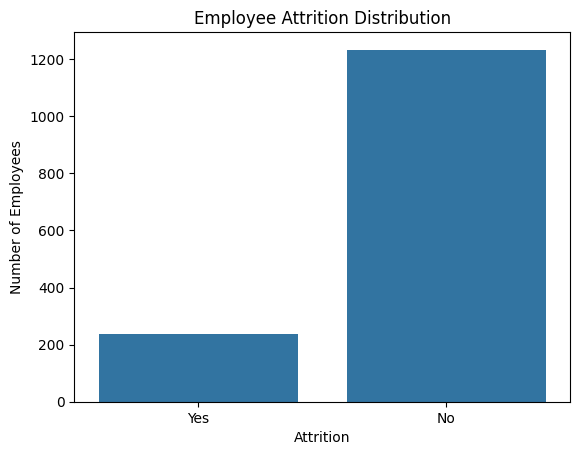

In [6]:
import matplotlib.pyplot as plt
import seaborn as sns

print("Attrition counts:")
print(df["Attrition"].value_counts())

print("\nAttrition percentages:")
print(
    (df["Attrition"].value_counts(normalize=True) * 100).round(2)
)

sns.countplot(data=df, x="Attrition")
plt.title("Employee Attrition Distribution")
plt.xlabel("Attrition")
plt.ylabel("Number of Employees")
plt.show()

# Prepare the dataset

In [7]:
# Create a working copy
df_clean = df.copy()

# Remove columns that are identifiers or constant values
columns_to_remove = [
    "EmployeeCount",
    "EmployeeNumber",
    "Over18",
    "StandardHours"
]

df_clean.drop(
    columns=columns_to_remove,
    inplace=True,
    errors="ignore"
)

# Convert target into numbers: No = 0, Yes = 1
df_clean["Attrition"] = df_clean["Attrition"].map({
    "No": 0,
    "Yes": 1
})

print("Dataset prepared successfully!")
print("New dataset shape:", df_clean.shape)
display(df_clean.head())

Dataset prepared successfully!
New dataset shape: (1470, 31)


,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EnvironmentSatisfaction,Gender,...,PerformanceRating,RelationshipSatisfaction,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,1,Travel_Rarely,1102,Sales,1,2,Life Sciences,2,Female,...,3,1,0,8,0,1,6,4,0,5
1,49,0,Travel_Frequently,279,Research & Development,8,1,Life Sciences,3,Male,...,4,4,1,10,3,3,10,7,1,7
2,37,1,Travel_Rarely,1373,Research & Development,2,2,Other,4,Male,...,3,2,0,7,3,3,0,0,0,0
3,33,0,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,4,Female,...,3,3,0,8,3,3,8,7,3,0
4,27,0,Travel_Rarely,591,Research & Development,2,1,Medical,1,Male,...,3,4,1,6,3,3,2,2,2,2


#Split the dataset

In [8]:
from sklearn.model_selection import train_test_split

# Separate input features and target
X = df_clean.drop("Attrition", axis=1)
y = df_clean["Attrition"]

# Split data: 80% training, 20% testing
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)
print("\nTraining target distribution:")
print(y_train.value_counts())

Training data: (1176, 30)
Testing data: (294, 30)

Training target distribution:
Attrition
0    986
1    190
Name: count, dtype: int64


#Convert categorical columns and scale numeric columns

In [9]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer

# Identify numeric and categorical columns
numeric_features = X_train.select_dtypes(
    include=["number"]
).columns.tolist()

categorical_features = X_train.select_dtypes(
    exclude=["number"]
).columns.tolist()

# Prepare numeric columns
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Prepare categorical columns
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine preprocessing
preprocessor = ColumnTransformer([
    ("num", numeric_pipeline, numeric_features),
    ("cat", categorical_pipeline, categorical_features)
])

print("Numeric columns:", len(numeric_features))
print("Categorical columns:", len(categorical_features))
print("Preprocessing setup completed!")

Numeric columns: 23
Categorical columns: 7
Preprocessing setup completed!


#Train the first model: Logistic Regression

In [10]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

# Create the model pipeline
logistic_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        max_iter=2000,
        random_state=42
    ))
])

# Train the model
logistic_model.fit(X_train, y_train)

# Make predictions
y_pred = logistic_model.predict(X_test)
y_prob = logistic_model.predict_proba(X_test)[:, 1]

# Evaluate the model
print("Logistic Regression Results")
print("----------------------------")
print("Accuracy:", round(accuracy_score(y_test, y_pred), 4))
print("Precision:", round(
    precision_score(y_test, y_pred, zero_division=0), 4
))
print("Recall:", round(
    recall_score(y_test, y_pred, zero_division=0), 4
))
print("F1-Score:", round(
    f1_score(y_test, y_pred, zero_division=0), 4
))
print("ROC-AUC:", round(roc_auc_score(y_test, y_prob), 4))

Logistic Regression Results
----------------------------
Accuracy: 0.8605
Precision: 0.6154
Recall: 0.3404
F1-Score: 0.4384
ROC-AUC: 0.8115


#Train the  models

In [11]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score
)
from sklearn.pipeline import Pipeline
import pandas as pd

# Define the models
models = {
    "Logistic Regression": LogisticRegression(
        max_iter=2000, random_state=42
    ),
    "Decision Tree": DecisionTreeClassifier(
        random_state=42, class_weight="balanced"
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=200, random_state=42,
        class_weight="balanced"
    )
}

results = []
trained_models = {}

# Train and evaluate each model
for name, classifier in models.items():
    model = Pipeline([
        ("preprocessor", preprocessor),
        ("classifier", classifier)
    ])

    model.fit(X_train, y_train)

    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(
            y_test, y_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_test, y_pred, zero_division=0
        ),
        "F1-Score": f1_score(
            y_test, y_pred, zero_division=0
        ),
        "ROC-AUC": roc_auc_score(y_test, y_prob)
    })

    trained_models[name] = model

results_df = pd.DataFrame(results)
print("Model Evaluation Results")
display(results_df.round(4))

Model Evaluation Results


,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Logistic Regression,0.8605,0.6154,0.3404,0.4384,0.8115
1,Decision Tree,0.7551,0.2642,0.2979,0.2800,0.5700
2,Random Forest,0.8469,0.6250,0.1064,0.1818,0.7832


#Add XGBoost

In [12]:
%pip -q install xgboost

In [13]:
from xgboost import XGBClassifier
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score
)

xgb_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", XGBClassifier(
        n_estimators=200,
        max_depth=4,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        eval_metric="logloss",
        random_state=42
    ))
])

xgb_model.fit(X_train, y_train)

y_pred = xgb_model.predict(X_test)
y_prob = xgb_model.predict_proba(X_test)[:, 1]

xgb_results = {
    "Model": "XGBoost",
    "Accuracy": accuracy_score(y_test, y_pred),
    "Precision": precision_score(y_test, y_pred, zero_division=0),
    "Recall": recall_score(y_test, y_pred, zero_division=0),
    "F1-Score": f1_score(y_test, y_pred, zero_division=0),
    "ROC-AUC": roc_auc_score(y_test, y_prob)
}

trained_models["XGBoost"] = xgb_model

results_df = pd.concat(
    [results_df, pd.DataFrame([xgb_results])],
    ignore_index=True
)

display(results_df.round(4))

,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Logistic Regression,0.8605,0.6154,0.3404,0.4384,0.8115
1,Decision Tree,0.7551,0.2642,0.2979,0.2800,0.5700
2,Random Forest,0.8469,0.6250,0.1064,0.1818,0.7832
3,XGBoost,0.8673,0.7857,0.2340,0.3607,0.7973


#Tune the best model

In [14]:
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline

# Create the model pipeline
lr_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        max_iter=3000,
        random_state=42
    ))
])

# Define hyperparameters to test
param_grid = {
    "classifier__C": [0.01, 0.1, 1, 10],
    "classifier__class_weight": [None, "balanced"],
    "classifier__solver": ["liblinear", "lbfgs"]
}

# Use 5-fold stratified cross-validation
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

grid_search = GridSearchCV(
    estimator=lr_pipeline,
    param_grid=param_grid,
    scoring="f1",
    cv=cv,
    n_jobs=-1,
    verbose=1
)

grid_search.fit(X_train, y_train)

print("Best Parameters:")
print(grid_search.best_params_)

print("\nBest Cross-Validation F1-Score:")
print(round(grid_search.best_score_, 4))

Fitting 5 folds for each of 16 candidates, totalling 80 fits
Best Parameters:
{'classifier__C': 1, 'classifier__class_weight': None, 'classifier__solver': 'liblinear'}

Best Cross-Validation F1-Score:
0.561


#Evaluate the tuned model

In [15]:
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, classification_report
)

best_model = grid_search.best_estimator_

y_pred_tuned = best_model.predict(X_test)
y_prob_tuned = best_model.predict_proba(X_test)[:, 1]

print("Tuned Logistic Regression Results")
print("---------------------------------")
print("Accuracy:", round(accuracy_score(y_test, y_pred_tuned), 4))
print("Precision:", round(precision_score(y_test, y_pred_tuned, zero_division=0), 4))
print("Recall:", round(recall_score(y_test, y_pred_tuned, zero_division=0), 4))
print("F1-Score:", round(f1_score(y_test, y_pred_tuned, zero_division=0), 4))
print("ROC-AUC:", round(roc_auc_score(y_test, y_prob_tuned), 4))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_tuned, zero_division=0))

Tuned Logistic Regression Results
---------------------------------
Accuracy: 0.8605
Precision: 0.6154
Recall: 0.3404
F1-Score: 0.4384
ROC-AUC: 0.8123

Classification Report:
              precision    recall  f1-score   support

           0       0.88      0.96      0.92       247
           1       0.62      0.34      0.44        47

    accuracy                           0.86       294
   macro avg       0.75      0.65      0.68       294
weighted avg       0.84      0.86      0.84       294



#Feature importance

In [16]:
import pandas as pd
import numpy as np

# Get feature names after preprocessing
feature_names = best_model.named_steps[
    "preprocessor"
].get_feature_names_out()

# Get Logistic Regression coefficients
coefficients = best_model.named_steps[
    "classifier"
].coef_[0]

importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Coefficient": coefficients,
    "Importance": np.abs(coefficients)
})

importance_df = importance_df.sort_values(
    by="Importance", ascending=False
)

print("Top 15 Important Features")
display(importance_df.head(15).round(4))

Top 15 Important Features


,Feature,Coefficient,Importance
49,cat__OverTime_No,-1.2484,1.2484
23,cat__BusinessTravel_Non-Travel,-1.1043,1.1043
42,cat__JobRole_Research Director,-1.0680,1.0680
39,cat__JobRole_Laboratory Technician,0.9853,0.9853
33,cat__EducationField_Other,-0.8174,0.8174
45,cat__JobRole_Sales Representative,0.7885,0.7885
24,cat__BusinessTravel_Travel_Frequently,0.6717,0.6717
37,cat__JobRole_Healthcare Representative,-0.6188,0.6188
50,cat__OverTime_Yes,0.5949,0.5949
27,cat__Department_Research & Development,-0.5778,0.5778
